# Practice #2. "Trend predictive models"

Measure forecast error, then forecast: naive, exponential smoothing,
Holt, Holt-Winters.

Fill in the cells tagged `graded`, keeping every name and signature exactly as
given — they are graded automatically.

**Contract.** Every `*_forecast(train, index, ...)` returns a `pd.Series` on
`index` — the timestamps you want predictions for. It may read `train` only; it
never sees the test values.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing

def find_data_dir():
    """The repo's data/ directory, wherever the kernel happens to start."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data" / "airline-passengers.csv").exists():
            return folder / "data"
    raise FileNotFoundError("data/ not found - run this notebook inside the repo")


DATA_DIR = globals().get("DATA_DIR", find_data_dir())

## 0. Data reading and splitting

In [2]:
def load_series(path, time_col, value_col):
    """Read a CSV into a float Series named "y" on a DatetimeIndex."""
    # Сначала выбираю только нужные колонки, и только потом удаляю пропуски,
    # чтобы NaN в других столбцах (как Wind/Solar в opsd_germany_daily) не выкинули хорошие строки.
    df = pd.read_csv(path, usecols=[time_col, value_col])
    df[time_col] = pd.to_datetime(df[time_col])
    df[value_col] = pd.to_numeric(df[value_col], errors="coerce")
    df = df.dropna(subset=[time_col, value_col]).sort_values(time_col)
    index = pd.DatetimeIndex(df[time_col], name=time_col)
    return pd.Series(df[value_col].to_numpy(dtype=float), index=index, name="y")


def train_test_split_ts(series, test_size):
    """Return (train, test); the LAST `test_size` points are the test set.

    Never shuffle a time series — a shuffled split lets the model see the future.
    """
    # Проверяю корректность размера теста и просто режу ряд по времени: начало в train, хвост в test.
    if test_size <= 0 or test_size >= len(series):
        raise ValueError("test_size должен быть больше 0 и меньше длины ряда")
    return series.iloc[:-test_size], series.iloc[-test_size:]

In [3]:
series = load_series(DATA_DIR / "daily-min-temperatures.csv", "Date", "Temp")
train, test = train_test_split_ts(series, test_size=365)
print(f"train: {len(train)} points, {train.index.min():%Y-%m-%d} to {train.index.max():%Y-%m-%d}")
print(f"test : {len(test)} points, {test.index.min():%Y-%m-%d} to {test.index.max():%Y-%m-%d}")

train: 3285 points, 1981-01-01 to 1989-12-31
test : 365 points, 1990-01-01 to 1990-12-31


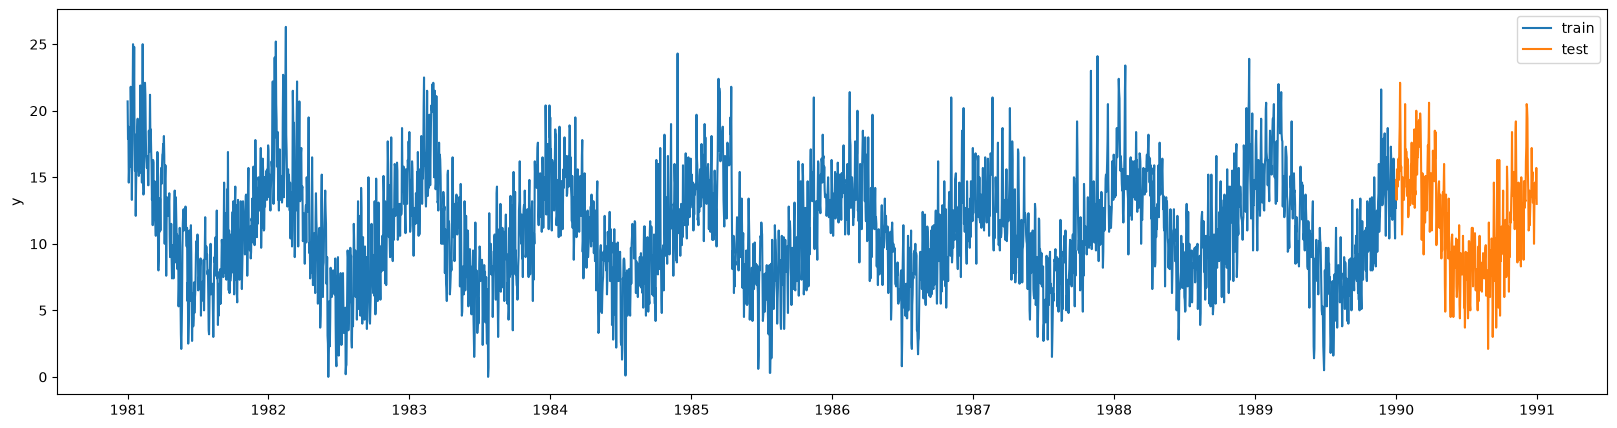

In [4]:
plt.figure(figsize=(20, 5))
plt.plot(train, label="train")
plt.plot(test, label="test")
plt.ylabel("y")
plt.legend();

## 1. Forecasting performance measures

Implement each one from its definition, then check against scikit-learn.

Keep the names straight: **MSE is squared error, RMSE is its square root.**
Different units — you cannot compare one to the other.

In [5]:
def forecast_error(actual, predicted):
    """actual - predicted, per point, as a numpy array."""
    # Перевожу оба входа в float-массивы numpy, чтобы функция работала и со списками, и с Series.
    return np.asarray(actual, dtype=float) - np.asarray(predicted, dtype=float)


def forecast_bias(actual, predicted):
    """Mean forecast error. Positive = the forecast runs low."""
    # Средняя ошибка со знаком: если > 0, значит прогноз в среднем занижает реальные значения.
    return float(np.mean(forecast_error(actual, predicted)))


def mae(actual, predicted):
    """Mean absolute error."""
    # Средний модуль ошибки — в тех же единицах, что и сам ряд.
    return float(np.mean(np.abs(forecast_error(actual, predicted))))


def mse(actual, predicted):
    """Mean squared error. Not the root — squared units."""
    # Средний квадрат ошибки (сильнее штрафует за крупные промахи).
    return float(np.mean(forecast_error(actual, predicted) ** 2))


def rmse(actual, predicted):
    """Root mean squared error — same units as the data."""
    # Корень из MSE, чтобы вернуться к исходным единицам измерения.
    return float(np.sqrt(mse(actual, predicted)))

In [6]:
actual = [0.5, 0.5, 0.5, 0.5]
predicted = [0.7, 0.5, 0.3, 0.2]

print("errors      ", forecast_error(actual, predicted))
print("bias (MFE)  ", forecast_bias(actual, predicted))
print("MAE         ", mae(actual, predicted))
print("MSE         ", mse(actual, predicted))
print("RMSE        ", rmse(actual, predicted))

assert np.isclose(mae(actual, predicted), mean_absolute_error(actual, predicted))
assert np.isclose(mse(actual, predicted), mean_squared_error(actual, predicted))
print("\nagrees with scikit-learn")

errors       [-0.2  0.   0.2  0.3]
bias (MFE)   0.07500000000000001
MAE          0.175
MSE          0.042499999999999996
RMSE         0.206155281280883

agrees with scikit-learn


**Question.** The bias is positive and the MAE is non-zero. What does
each tell you that the other does not?

**Ответ.** Положительный bias (`0.075`) показывает направление систематической ошибки: в среднем прогноз занижен относительно факта (`actual - predicted > 0`). Но bias может быть близок к нулю или мал даже при больших ошибках, если положительные и отрицательные промахи взаимно гасят друг друга (здесь `-0.2` компенсировало часть `+0.2` и `+0.3`). MAE (`0.175`) измеряет средний масштаб ошибки без учёта знака — то есть насколько в среднем прогноз расходится с реальностью, но не говорит, в какую сторону он смещён.

In [7]:
def plot_forecast(train, test, forecast, title):
    """Plot the tail of the training data next to the test data and a forecast."""
    plt.figure(figsize=(20, 5))
    plt.plot(train.iloc[-3 * len(test):], label="train")
    plt.plot(test, label="test")
    plt.plot(forecast, label="forecast")
    plt.title(f"{title} — RMSE {rmse(test, forecast):.3f}")
    plt.legend()
    plt.show()

## 2. Naive approaches

### 2.1 Naive forecast

The last observed value, carried forward. Every model below has to beat it or it
is not worth its complexity.

In [8]:
def naive_forecast(train, index):
    """Last observed value, repeated over `index`."""
    # Беру последнее известное значение из train и тяну его константой на весь индекс теста.
    last_val = float(train.iloc[-1])
    return pd.Series(last_val, index=index, name="y", dtype=float)


def moving_average_forecast(train, index, window):
    """Mean of the last `window` observations, repeated over `index`."""
    # Усредняю последние window точек из train и использую это число как плоский прогноз.
    if window <= 0:
        raise ValueError("window должен быть положительным")
    mean_val = float(train.iloc[-window:].mean())
    return pd.Series(mean_val, index=index, name="y", dtype=float)


def linear_regression_forecast(train, index):
    """Fit a line on 0..len(train)-1 and extrapolate over `index`."""
    # Обучаю линейную регрессию на номерах шагов 0..N-1 и продолжаю прямую на N..N+H-1.
    n = len(train)
    x_train = np.arange(n, dtype=float).reshape(-1, 1)
    y_train = train.to_numpy(dtype=float)
    model = LinearRegression()
    model.fit(x_train, y_train)
    x_future = np.arange(n, n + len(index), dtype=float).reshape(-1, 1)
    preds = model.predict(x_future)
    return pd.Series(preds, index=index, name="y", dtype=float)

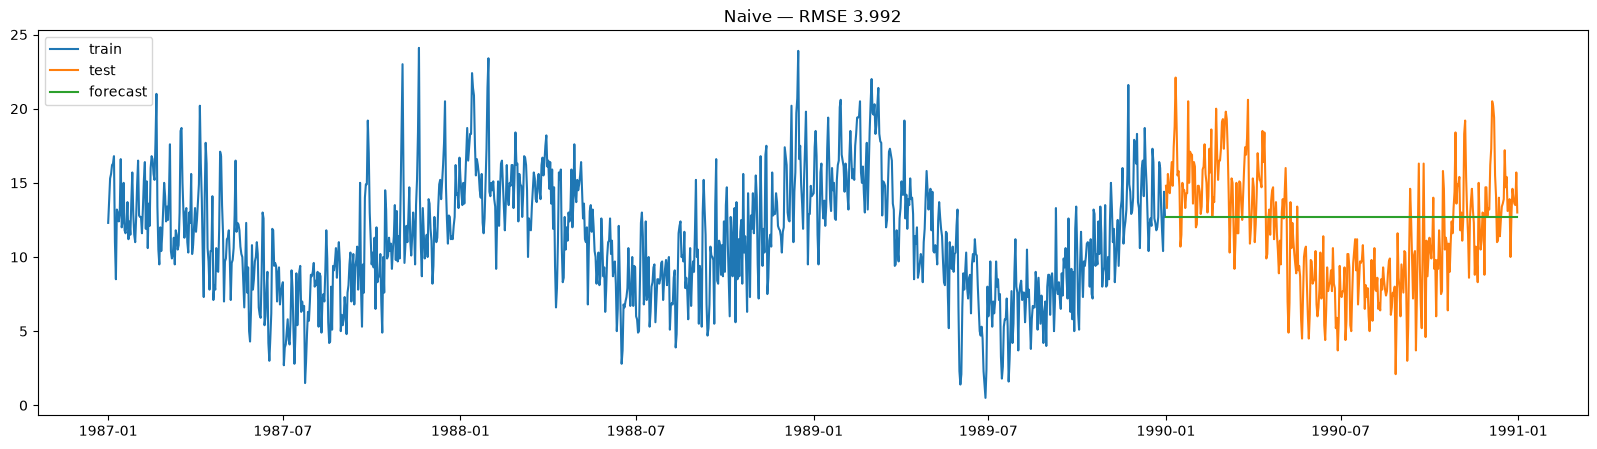

In [9]:
plot_forecast(train, test, naive_forecast(train, test.index), "Naive")

### 2.2 Moving average and 2.3 linear regression

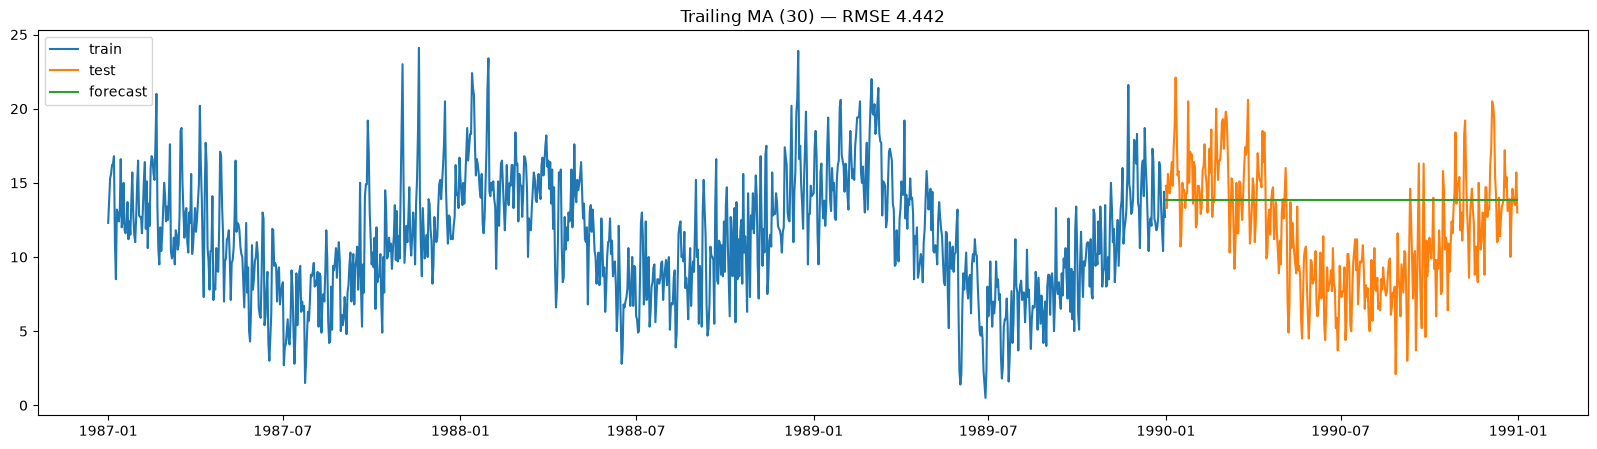

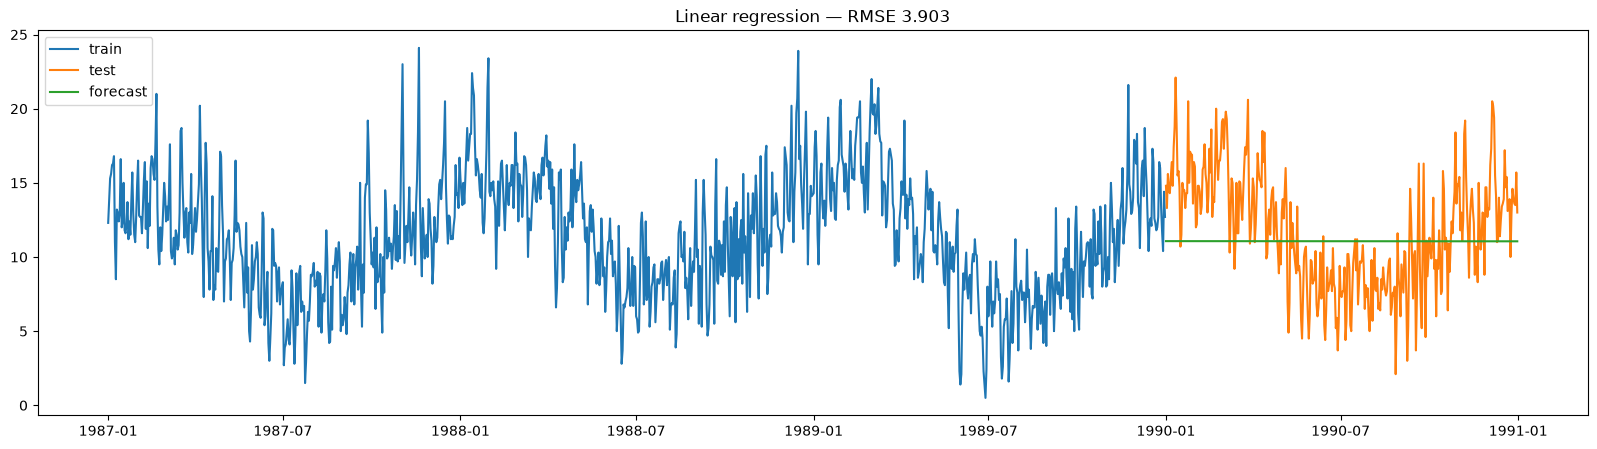

In [10]:
plot_forecast(train, test, moving_average_forecast(train, test.index, 30),
              "Trailing MA (30)")
plot_forecast(train, test, linear_regression_forecast(train, test.index),
              "Linear regression")

Find the window size with the lowest RMSE on the test set.

**Question.** That tuned a hyper-parameter *on the test set*. Why is the
resulting RMSE not your expected future error, and what should you have split
off instead?

**Ответ.** Если подбирать размер окна напрямую на тестовой выборке, модель косвенно «подсматривает» в тест: значение `RMSE = 3.8778` для `window = 365` оптимистично занижено, потому что это окно оказалось лучшим именно на этом конкретном году (`1990`), и на новых данных ошибка, скорее всего, будет выше. Вместо этого нужно отрезать отдельную валидационную выборку (или делать скользящую кросс-валидацию на `train`), подобрать `window` там, а на `test` измерить итоговое качество один раз в самом конце.

In [11]:
scores = {w: rmse(test, moving_average_forecast(train, test.index, w))
          for w in (7, 14, 30, 60, 90, 180, 365)}
for window, score in sorted(scores.items(), key=lambda kv: kv[1]):
    print(f"window {window:>4}: RMSE {score:.4f}")

window  365: RMSE 3.8778
window   90: RMSE 3.9093
window   60: RMSE 4.2737
window    7: RMSE 4.2935
window   14: RMSE 4.2998
window  180: RMSE 4.3057
window   30: RMSE 4.4416


## 3. Simple Exponential Smoothing

In [12]:
def ses_forecast(train, index, alpha):
    """SES forecast — a flat line at the final level."""
    # Передаю numpy-массив, чтобы statsmodels не ругался на нерегулярную частоту дат,
    # а затем оборачиваю прогноз обратно в Series с нужным индексом.
    model = SimpleExpSmoothing(
        train.to_numpy(dtype=float),
        initialization_method="known",
        initial_level=float(train.iloc[0]),
    )
    fitted = model.fit(smoothing_level=alpha, optimized=False)
    preds = fitted.forecast(len(index))
    return pd.Series(preds, index=index, name="y", dtype=float)


def holt_forecast(train, index, alpha, beta, trend="add"):
    """Holt forecast — level plus an extrapolated slope."""
    # Модель Хольта добавляет к уровню ещё и сглаженный тренд (наклон) без сезонности.
    model = ExponentialSmoothing(
        train.to_numpy(dtype=float),
        trend=trend,
        seasonal=None,
        initialization_method="estimated",
    )
    fitted = model.fit(smoothing_level=alpha, smoothing_trend=beta, optimized=False)
    preds = fitted.forecast(len(index))
    return pd.Series(preds, index=index, name="y", dtype=float)


def holt_winters_forecast(train, index, seasonal_periods, trend="add",
                          seasonal="add"):
    """Holt-Winters forecast; let statsmodels optimise the parameters.

    Raise ValueError on less than two full seasons of training data.
    """
    # Для оценки сезонных компонент нужно хотя бы два полных цикла наблюдений.
    if len(train) < 2 * seasonal_periods:
        raise ValueError(
            f"Для Holt-Winters нужно минимум 2 полных сезона ({2 * seasonal_periods} точек), "
            f"а в train только {len(train)}"
        )
    model = ExponentialSmoothing(
        train.to_numpy(dtype=float),
        trend=trend,
        seasonal=seasonal,
        seasonal_periods=seasonal_periods,
        initialization_method="estimated",
    )
    fitted = model.fit(optimized=True)
    preds = fitted.forecast(len(index))
    return pd.Series(preds, index=index, name="y", dtype=float)

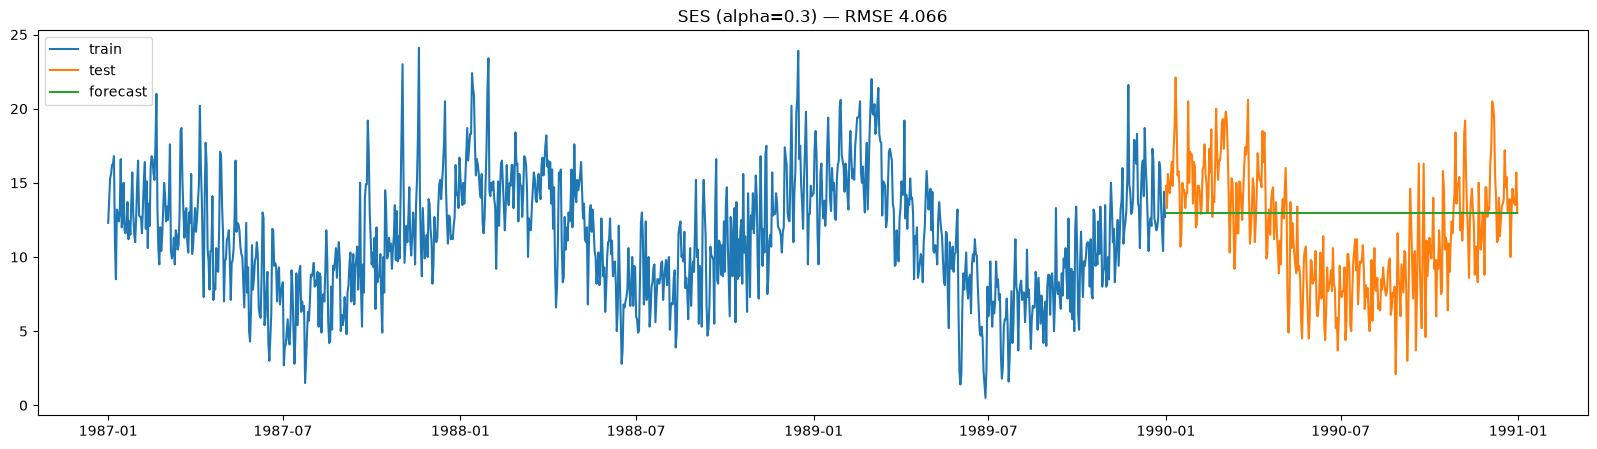

In [13]:
plot_forecast(train, test, ses_forecast(train, test.index, 0.3), "SES (alpha=0.3)")

**Question.** The SES forecast is a horizontal line. Why, from the
recursion? And when is a flat forecast the *right* answer?

**Ответ.** В SES уровень обновляется рекурсивно: $\hat{y}_{t+1|t} = \ell_t = \alpha y_t + (1 - \alpha)\ell_{t-1}$, а для любого горизонта $h \ge 1$ прогноз равен последнему оценённому уровню $\hat{y}_{T+h|T} = \ell_T$, потому что в модели нет ни тренда, ни сезонности — будущее считается стационарным вокруг текущего уровня. Такой плоский прогноз уместен, когда у ряда действительно нет выраженного тренда и сезонности (случайное блуждание или колебания вокруг медленно меняющегося среднего уровня), либо на очень коротком горизонте.

## 4. Holt's Linear Trend Model

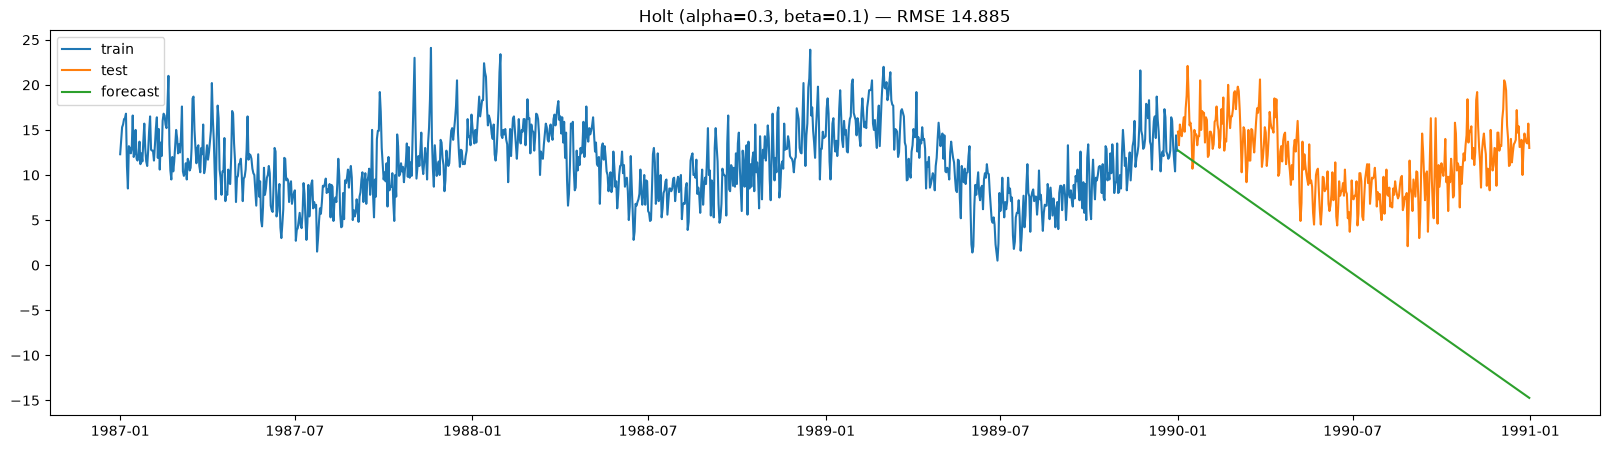

In [14]:
plot_forecast(train, test, holt_forecast(train, test.index, 0.3, 0.1),
              "Holt (alpha=0.3, beta=0.1)")

**Question.** Holt is the more powerful model — did it beat naive here?
What does the answer say about daily minimum temperatures?

**Ответ.** Нет, модель Хольта (`RMSE = 14.8851`) выступила намного хуже даже простого наивного прогноза (`RMSE = 3.9916`). Причина в том, что на конце обучающей выборки (`1989-12-31`, южное полушарие, лето) температура высокая и растёт, и Хольт линейно экстраполировал этот локальный наклон на целый год вперёд, хотя на деле у суточных минимальных температур в Мельбурне нет долгосрочного линейного тренда — вместо него есть сильный годовой сезонный цикл.

## 5. Holt-Winters' model

The series has a yearly cycle. On daily data that means `seasonal_periods=365` —
365 seasonal parameters, estimated from 9 years. Slow and badly determined.
Resampling to monthly means captures the same cycle with 12.

Match the resolution of the data to the resolution of the pattern.

monthly: 120 points; train 96, test 24


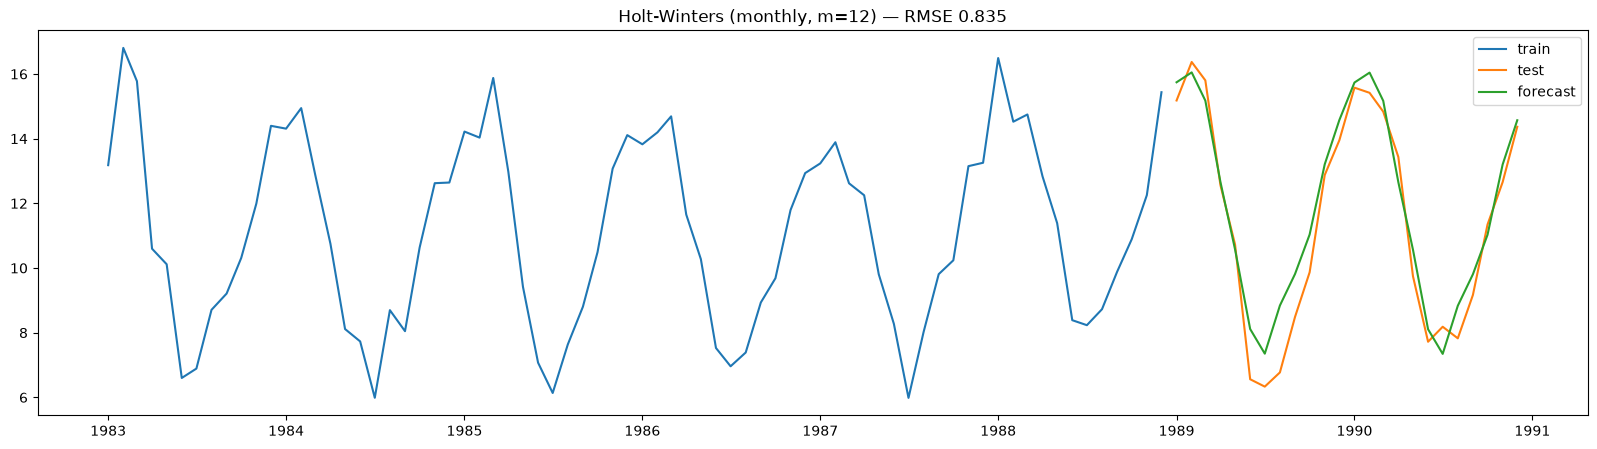

In [15]:
monthly = series.resample("MS").mean()
m_train, m_test = train_test_split_ts(monthly, test_size=24)
print(f"monthly: {len(monthly)} points; train {len(m_train)}, test {len(m_test)}")

hw = holt_winters_forecast(m_train, m_test.index, seasonal_periods=12)
plot_forecast(m_train, m_test, hw, "Holt-Winters (monthly, m=12)")

In [16]:
baseline = naive_forecast(m_train, m_test.index)
print(f"naive         RMSE {rmse(m_test, baseline):.4f}")
print(f"Holt-Winters  RMSE {rmse(m_test, hw):.4f}")

naive         RMSE 5.1159
Holt-Winters  RMSE 0.8348


Try `trend` and `seasonal` as `"add"` and `"mul"`.

**Questions.** Which combination wins? And why does multiplicative seasonality
make little sense in degrees Celsius — what happens to it near zero?

**Ответ.** На месячных данных с большим отрывом от наивного прогноза (`RMSE = 5.1159`) побеждает Хольт-Винтерс: лучшей по RMSE оказалась комбинация `trend="mul", seasonal="mul"` (`RMSE = 0.7554`), рядом с ней `trend="add", seasonal="mul"` (`0.7603`), а чисто аддитивная `("add", "add")` дала `0.8348`. Однако физически мультипликативная сезонность для градусов Цельсия некорректна: шкала Цельсия интервальная, а не шкала отношений, её ноль условен. Когда уровень ряда $\ell_t$ приближается к $0\,^\circ\text{C}$ (или уходит в минус), умножение на сезонный коэффициент либо схлопывает сезонную амплитуду к нулю, либо переворачивает знак, а при делении на околонулевой уровень в оценке сезонности модель вообще теряет устойчивость.

trend=add, seasonal=add -> RMSE = 0.8348
trend=add, seasonal=mul -> RMSE = 0.7603


trend=mul, seasonal=add -> RMSE = 0.8209


trend=mul, seasonal=mul -> RMSE = 0.7554

Лучшая комбинация: trend=mul, seasonal=mul (RMSE 0.7554)


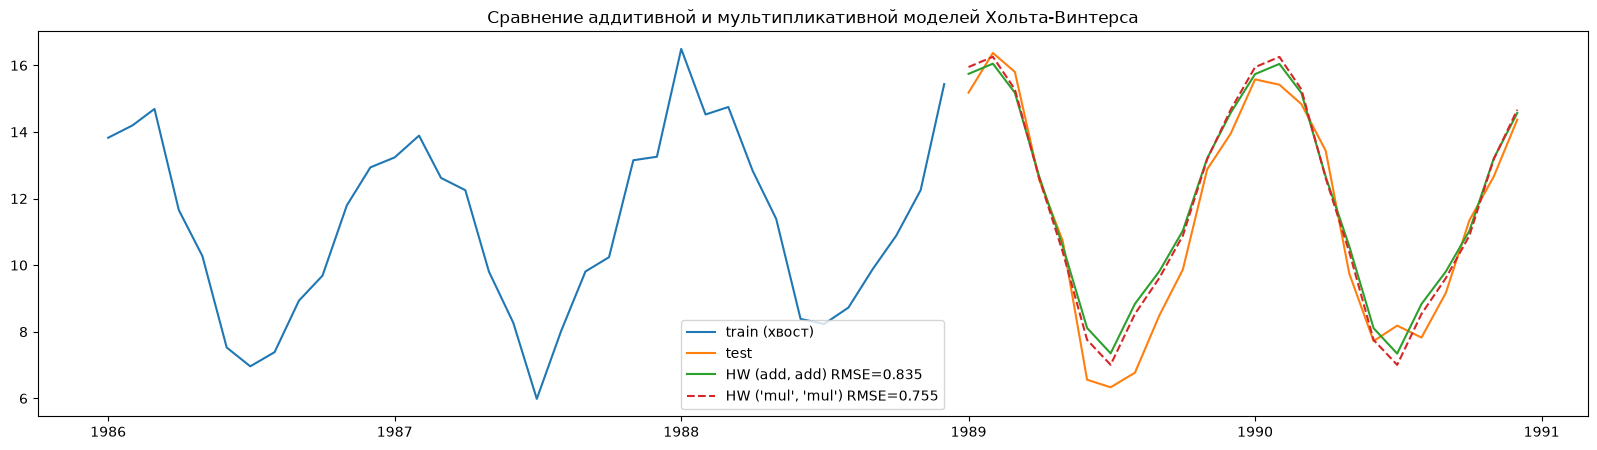

In [17]:
# Свободное исследование: сравню все 4 комбинации trend и seasonal ("add" и "mul") для Хольта-Винтерса
results = {}
for tr in ("add", "mul"):
    for se in ("add", "mul"):
        fc = holt_winters_forecast(m_train, m_test.index, seasonal_periods=12, trend=tr, seasonal=se)
        results[(tr, se)] = (rmse(m_test, fc), fc)
        print(f"trend={tr}, seasonal={se} -> RMSE = {results[(tr, se)][0]:.4f}")

# Нарисую лучшую модель и чисто аддитивную для сравнения
best_key = min(results, key=lambda k: results[k][0])
print(f"\nЛучшая комбинация: trend={best_key[0]}, seasonal={best_key[1]} (RMSE {results[best_key][0]:.4f})")

plt.figure(figsize=(20, 5))
plt.plot(m_train.iloc[-36:], label="train (хвост)")
plt.plot(m_test, label="test")
plt.plot(results[("add", "add")][1], label=f"HW (add, add) RMSE={results[('add', 'add')][0]:.3f}")
plt.plot(results[best_key][1], "--", label=f"HW {best_key} RMSE={results[best_key][0]:.3f}")
plt.title("Сравнение аддитивной и мультипликативной моделей Хольта-Винтерса")
plt.legend()
plt.show()